Уровень 1
1. Найти производную функции \(f(x) = \sin(\frac{1}{x})\) в точке \(x_0 = 5\)
Решение:
Сначала найдем производную функции, используя правило дифференцирования сложной функции:
\(f'(x) = \cos(\frac{1}{x}) \cdot (-\frac{1}{x^2}) = -\frac{\cos(\frac{1}{x})}{x^2}\)
Подставляем заданную точку \(x_0 = 5\):
\(f'(5) = -\frac{\cos(\frac{1}{5})}{5^2} = -\frac{\cos(0.2)}{25}\)
Ответ: \(-\frac{\cos(0.2)}{25}\) (примерно \(-0.0391\))
2. Найти производную функции \(f(x) = e^{-\frac{x}{2}}\) в точке \(x_0 = 2\)
Решение:
По правилу дифференцирования сложной функции:
\(f'(x) = e^{-\frac{x}{2}} \cdot (-\frac{x}{2})' = -\frac{1}{2}e^{-\frac{x}{2}}\)
Подставляем заданную точку \(x_0 = 2\):
\(f'(2) = -\frac{1}{2}e^{-\frac{2}{2}} = -\frac{1}{2e}\)
Ответ: \(-\frac{1}{2e}\) (примерно \(-0.1839\))
3. Найти градиент \(\nabla f\) в точке \(x_0 = (2, 10)\) для функции \(f(x, y) = (x + y)^2 - 3y + 5\)
Решение:
Найдем частные производные по каждой переменной:
\(\frac{\partial f}{\partial x} = 2(x + y)\)
\(\frac{\partial f}{\partial y} = 2(x + y) - 3\)
Подставим координаты точки \(x_0 = (2, 10)\). Сумма \(x + y = 2 + 10 = 12\).
\(\frac{\partial f}{\partial x}(2, 10) = 2 \cdot 12 = 24\)
\(\frac{\partial f}{\partial y}(2, 10) = 2 \cdot 12 - 3 = 21\)
Ответ: \(\nabla f(2, 10) = (24, 21)\)
4. Найти градиент \(\nabla f\) в точке \(x_0 = (-1, -5, 0)\) для функции \(f(x, y, z) = (x + y - z)^2 - 3(y + z)^2\)
Решение:
Найдем частные производные по \(x\), \(y\) и \(z\):
\(\frac{\partial f}{\partial x} = 2(x + y - z)\)
\(\frac{\partial f}{\partial y} = 2(x + y - z) - 6(y + z)\)
\(\frac{\partial f}{\partial z} = -2(x + y - z) - 6(y + z)\)
Подставим координаты точки \(x_0 = (-1, -5, 0)\). 
Считаем внутренние скобки: 
\((x + y - z) = -1 - 5 - 0 = -6\)
\((y + z) = -5 + 0 = -5\)
Вычисляем значения производных:
\(\frac{\partial f}{\partial x} = 2 \cdot (-6) = -12\)
\(\frac{\partial f}{\partial y} = 2 \cdot (-6) - 6 \cdot (-5) = -12 + 30 = 18\)
\(\frac{\partial f}{\partial z} = -2 \cdot (-6) - 6 \cdot (-5) = 12 + 30 = 42\)
Ответ: \(\nabla f(-1, -5, 0) = (-12, 18, 42)\)

In [2]:
# Уровень 2
import numpy as np
from scipy.optimize import minimize

# 1. Реализация градиентного спуска
def f(x, y):
    return (x - 3)**2 + (y + 5)**2

def grad_f(x, y):
    return np.array([2 * (x - 3), 2 * (y + 5)])

def gradient_descent(start_point, learning_rate, epsilon=1e-8, max_iters=10000):
    point = np.array(start_point, dtype=float)
    for i in range(max_iters):
        grad = grad_f(point[0], point[1])
        if np.linalg.norm(grad) < epsilon:
            return point, i
        point = point - learning_rate * grad
    return point, max_iters
# Подбор learning rate и запуск 
# Возьмем 0.1
lr = 0.1
start_x0 = (5, 2)
min_point, iterations = gradient_descent(start_x0, lr, epsilon=1e-8)

print("Градиентный спуск")
print(f"Найденный минимум: x = {min_point[0]:.8f}, y = {min_point[1]:.8f}")
print(f"Количество итераций: {iterations}")

# 2. Проверка через scipy.optimize.minimize
res = minimize(lambda vars: f(vars[0], vars[1]), x0=start_x0)
print("\n Проверка через scipy.optimize.minimize")
print(f"Минимум по scipy: x = {res.x[0]:.8f}, y = {res.x[1]:.8f}")

Градиентный спуск
Найденный минимум: x = 3.00000000, y = -5.00000000
Количество итераций: 95

 Проверка через scipy.optimize.minimize
Минимум по scipy: x = 3.00000178, y = -5.00000087


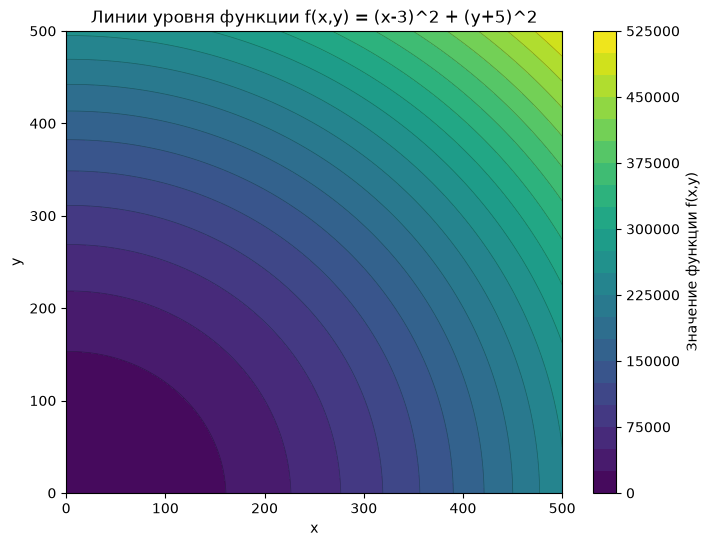

In [3]:
# Уровень 3
import matplotlib.pyplot as plt
import numpy as np

# Задаем сетку (как на скриншоте в задании: от 0 до 500)
x_vals = np.linspace(0, 500, 200)
y_vals = np.linspace(0, 500, 200)
X, Y = np.meshgrid(x_vals, y_vals)

# Вычисляем значения функции Z для каждой точки сетки
Z = (X - 3)**2 + (Y + 5)**2

# Строим график
plt.figure(figsize=(8, 6))

# Используем contourf для закрашенных областей (cmap='viridis' похож на цветовую схему из задания)
contour_filled = plt.contourf(X, Y, Z, levels=20, cmap='viridis')

# Добавляем сами линии контура (чтобы границы были видны)
plt.contour(X, Y, Z, levels=20, colors='black', alpha=0.3, linewidths=0.5)

# Добавляем цветовую шкалу
plt.colorbar(contour_filled, label='Значение функции f(x,y)')

plt.title('Линии уровня функции f(x,y) = (x-3)^2 + (y+5)^2')
plt.xlabel('x')
plt.ylabel('y')

plt.show()